## Lecture 10

In [1]:
from datascience import *
import numpy as np

%matplotlib inline
import matplotlib.pyplot as plots
plots.style.use('fivethirtyeight')

### Simulating Coin Flips

In [2]:
coin = make_array('Heads', 'Tails')

Use `np.random.choice(..)` to pick randomly from an array one of two ways:
- `np.random.choice(some_array)`
- `np.random.choice(some_array, n)`

In [101]:
np.random.choice(coin)

'Heads'

In [110]:
ten_tosses = np.random.choice(coin, 10)
ten_tosses

array(['Heads', 'Heads', 'Tails', 'Heads', 'Heads', 'Tails', 'Heads',
       'Heads', 'Tails', 'Heads'],
      dtype='<U5')

In [112]:
sum(ten_tosses == 'Heads')

7

Use `np.append(..)` to append values onto the end of an array one of two ways:
- `np.append(array_1, value)`
- `np.append(array_1, array_2)`

In [114]:
# I want to see how many times I get heads when I flip 100 coins
# And I want to do 10 trials of this
outcomes = make_array()

In [116]:
# [trial 1] how do i add trial2 onto the end?
# [trial1, trial2]
# [] append trial1
# [trial1] append trial2
# [trial1, trial2] append trial3

In [164]:
for i in np.arange(4):
    print(i)

0
1
2
3


In [165]:
outcomes = make_array()
iterations = 1000

# Instead of me pressing enter 10 times, I can write a loop to say 
# "Run this code 10 times
for i in np.arange(iterations):
    one_simulated_run = heads_in_hundred_tosses()
    outcomes = np.append(outcomes, one_simulated_run)

outcomes

array([ 55.,  45.,  42.,  41.,  44.,  51.,  51.,  51.,  52.,  52.,  58.,
        48.,  42.,  50.,  46.,  47.,  48.,  51.,  50.,  56.,  44.,  46.,
        55.,  56.,  42.,  51.,  46.,  34.,  60.,  56.,  47.,  50.,  47.,
        45.,  58.,  41.,  39.,  45.,  48.,  52.,  50.,  54.,  48.,  41.,
        54.,  54.,  63.,  46.,  39.,  51.,  52.,  50.,  46.,  44.,  60.,
        55.,  46.,  47.,  54.,  43.,  44.,  51.,  53.,  49.,  43.,  44.,
        48.,  52.,  53.,  55.,  55.,  42.,  53.,  45.,  55.,  41.,  44.,
        44.,  42.,  47.,  39.,  52.,  48.,  62.,  49.,  52.,  53.,  58.,
        44.,  52.,  43.,  42.,  48.,  50.,  46.,  52.,  40.,  54.,  52.,
        53.,  53.,  48.,  51.,  48.,  48.,  49.,  50.,  49.,  46.,  56.,
        43.,  59.,  46.,  50.,  53.,  48.,  44.,  53.,  47.,  40.,  44.,
        59.,  55.,  50.,  48.,  56.,  51.,  36.,  50.,  43.,  37.,  52.,
        47.,  49.,  58.,  50.,  47.,  45.,  47.,  50.,  47.,  48.,  42.,
        34.,  51.,  53.,  50.,  52.,  59.,  54.,  4

In [166]:
simulation_results = Table().with_columns('Repetition', np.arange(1, iterations+1),
                                          'Number of Heads', outcomes)
simulation_results

Repetition,Number of Heads
1,55
2,45
3,42
4,41
5,44
6,51
7,51
8,51
9,52
10,52


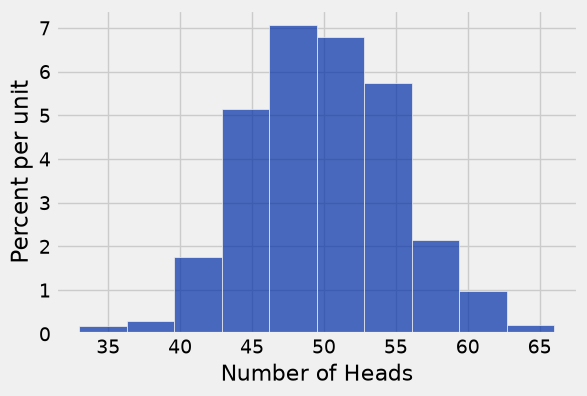

In [167]:
simulation_results.hist('Number of Heads')

In [162]:
heads_in_hundred_tosses()

45

In [137]:
def heads_in_hundred_tosses():
    hundred_tosses = make_array()
    for i in np.arange(100):
        hundred_tosses = np.append(hundred_tosses, np.random.choice(coin)
    # hundred_tosses = np.random.choice(coin, 100)
    return sum(hundred_tosses == 'Heads')

**Question: What is the chance of getting 50 heads in 100 coin flips?**

### The Monty Hall Problem is a Great Case to Simulate! ###

In [213]:
goats = make_array('first goat', 'second goat')
doors = make_array('car', 'first goat', 'second goat')
doors

array(['car', 'first goat', 'second goat'],
      dtype='<U11')

A goat is always revealed. First, we'll define a function that determines which goat is revealed.

In [214]:
def other_goat(x):
    if x == 'first goat':
        return 'second goat'
    elif x == 'second goat':
        return 'first goat'
    else:
        return 'not a goat'

In [215]:
other_goat('first goat')

'second goat'

In [216]:
other_goat('second goat')

'first goat'

In [217]:
other_goat('aaaaaa')

'not a goat'

In [221]:
def monty_hall():
    """Return 
    array([contestant's guess, what Monty reveals, what remains behind the other door])"""

    # Contensant randomly chooses one of three doors
    contestant_choice = np.random.choice(doors)

    # Scenario 1: Contensant chose goat 1  
    # Scenario 2: Contestnant chose goat 2
    if contestant_choice == 'first goat' or contestant_choice == 'second goat':
        monty_choice = other_goat(contestant_choice)
        remaining_choice = 'car'
    # Scenario 3: Consentant chose car
    else:
        monty_choice = np.random.choice(goats)
        remaining_choice = other_goat(monty_choice)
    
    return make_array(contestant_choice, monty_choice, remaining_choice)

In [227]:
monty_hall()

array(['second goat', 'first goat', 'car'],
      dtype='<U11')

### Types of samples

In [168]:
united = Table.read_table('united.csv')
united = united.with_column('Row', np.arange(united.num_rows)).move_to_start('Row')
united

Row,Date,Flight Number,Destination,Delay
0,6/1/15,73,HNL,257
1,6/1/15,217,EWR,28
2,6/1/15,237,STL,-3
3,6/1/15,250,SAN,0
4,6/1/15,267,PHL,64
5,6/1/15,273,SEA,-6
6,6/1/15,278,SEA,-8
7,6/1/15,292,EWR,12
8,6/1/15,300,HNL,20
9,6/1/15,317,IND,-10


#### **Task**: Take a convenience sample of size 5 from the `united` table. 

In [177]:
united.take(np.arange(5))

Row,Date,Flight Number,Destination,Delay
0,6/1/15,73,HNL,257
1,6/1/15,217,EWR,28
2,6/1/15,237,STL,-3
3,6/1/15,250,SAN,0
4,6/1/15,267,PHL,64


#### **Task**: Take some *determinstic* samples of 5 rows from the `united` table.

In [188]:
united.where('Destination', 'JFK').take(np.arange(5))

Row,Date,Flight Number,Destination,Delay
26,6/1/15,502,JFK,-4
33,6/1/15,637,JFK,141
39,6/1/15,704,JFK,-8
50,6/1/15,758,JFK,-5
51,6/1/15,760,JFK,352


In [190]:
united.take(np.arange(75,100,5))

Row,Date,Flight Number,Destination,Delay
75,6/1/15,1138,MSY,10
80,6/1/15,1185,EWR,97
85,6/1/15,1204,SEA,4
90,6/1/15,1263,ORD,148
95,6/1/15,1291,BOS,-2


#### **Task**: Take some *random* samples of 5 rows from the `united` table.

In [212]:
united.sample(5, with_replacement=False)

Row,Date,Flight Number,Destination,Delay
12008,8/19/15,760,JFK,0
913,6/7/15,401,CLE,-5
7016,7/17/15,1725,OGG,8
4558,7/1/15,868,IAD,4
5926,7/10/15,1602,ATL,6
